# Clase 14: Audio como dato — UT4, actividad 14

**Nombre:** Marcos Devincenzi  
**Curso:** Ingeniería de Datos — Universidad Católica del Uruguay

[Consigna](https://juanfkurucz.com/ucu-id/ut4/14-audio/).

**Objetivo:** cargar e inspeccionar audio, estandarizarlo, evaluar ruido/filtrado, extraer MFCC y exportar features para ML. Se resuelven A–D, las exploraciones E.1–E.3 y los extras F.1–F.3.

**Alcance de los datos:** UrbanSound8K contiene 8732 clips, 10 clases y 10 folds. Se incluye un subconjunto reproducible de **200 WAV reales**, dos por clase y fold. El pipeline principal utiliza 100 (slot 0), como el límite de la celda guía; QA utiliza los 200. Los inventarios del conjunto completo y de la selección se informan por separado. Los resultados del modelo no se presentan como un benchmark sobre todos los 8732 clips.

**Criterios de evaluación:** ruido añadido con SNR medido, features calculados sobre la salida real de cada pipeline y test separado por folds. No se estima un SNR verdadero del audio de campo sin referencia: para QA se informa un proxy de contraste de energía con sus limitaciones.

## Setup y Carga de Datos
### Instalación rápida

In [ ]:
# Solo si faltan dependencias:
# %pip install librosa==0.11.0 soundfile kagglehub numpy pandas matplotlib scipy scikit-learn ipykernel

In [1]:
from pathlib import Path
import os, json, io, base64, contextlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
import kagglehub
from scipy import signal
from IPython.display import HTML
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 16)
print('librosa:', librosa.__version__, '| soundfile:', sf.__version__, '| NumPy:', np.__version__)

librosa: 0.11.0 | soundfile: 0.13.1 | NumPy: 2.5.3


## 0) Dataset
Fuente: [UrbanSound8K en Kaggle](https://www.kaggle.com/datasets/chrisfilo/urbansound8k), publicado originalmente por el [Urban Sound Research Group](https://urbansounddataset.weebly.com/urbansound8k.html).

Se usa `kagglehub.dataset_download` con `path=` para descargar metadata y WAV seleccionados, evitando descargar archivos que no se analizan. Los datos incluidos permiten repetir la entrega sin credenciales. En una descarga nueva Kaggle puede solicitar autenticación; el contexto siguiente admite token moderno o ruta privada de `kaggle.json`, sin escribir secretos en la entrega. En Colab se puede subir el archivo privado desde su panel de archivos y pasar su ruta. No imprimir ni entregar sus credenciales.

In [2]:
RAW_DIR = Path('data/raw')
META_DIR = Path('data/metadata')
RAW_DIR.mkdir(parents=True, exist_ok=True)
META_DIR.mkdir(parents=True, exist_ok=True)
DATASET_HANDLE = 'chrisfilo/urbansound8k'

@contextlib.contextmanager
def kaggle_session(token=None, json_path=None):
    keys = ['KAGGLE_API_TOKEN', 'KAGGLE_USERNAME', 'KAGGLE_KEY']
    previous = {key: os.environ.get(key) for key in keys}
    credentials = {}
    try:
        if token:
            os.environ['KAGGLE_API_TOKEN'] = token
        elif json_path:
            credentials = json.loads(Path(json_path).read_text(encoding='utf-8'))
            os.environ['KAGGLE_USERNAME'] = credentials['username']
            os.environ['KAGGLE_KEY'] = credentials['key']
        yield
    finally:
        credentials.clear()
        for key, value in previous.items():
            if value is None:
                os.environ.pop(key, None)
            else:
                os.environ[key] = value

metadata_path = META_DIR / 'UrbanSound8K.csv'
if not metadata_path.exists():
    kagglehub.dataset_download(DATASET_HANDLE, path='UrbanSound8K.csv', output_dir=str(META_DIR))
metadata = pd.read_csv(metadata_path)
selection_path = META_DIR / 'seleccion_200.csv'
if not selection_path.exists():
    parts = []
    for (fold, class_id), group in metadata.groupby(['fold', 'classID'], sort=True):
        independent = group.sort_values(['fsID', 'slice_file_name']).drop_duplicates('fsID')
        candidates = independent if len(independent) >= 2 else group
        chosen = candidates.sample(2, random_state=SEED + int(fold)*10 + int(class_id)).sort_values('slice_file_name').copy()
        chosen['selection_slot'] = [0, 1]
        parts.append(chosen)
    selection = pd.concat(parts, ignore_index=True).sort_values(['fold', 'classID', 'selection_slot'])
    selection['relative_path'] = [f'fold{f}/{name}' for f, name in zip(selection.fold, selection.slice_file_name)]
    selection.to_csv(selection_path, index=False)
selection = pd.read_csv(selection_path)
for relative in selection.relative_path:
    if not (RAW_DIR / relative).exists():
        kagglehub.dataset_download(DATASET_HANDLE, path=relative, output_dir=str(RAW_DIR))
audio_files = [RAW_DIR / relative for relative in selection.relative_path]
core_selection = selection.loc[selection.selection_slot == 0].copy()
core_files = [RAW_DIR / relative for relative in core_selection.relative_path]
assert len(metadata) == 8732 and metadata['classID'].nunique() == 10
assert len(audio_files) == 200 and len(core_files) == 100
assert selection.groupby(['fold', 'classID']).size().eq(2).all()
assert all(path.is_file() for path in audio_files)
print('Inventario completo:', len(metadata), '| WAV incluidos:', len(audio_files), '| núcleo:', len(core_files))
selection.groupby(['fold', 'classID']).size().unstack(fill_value=0)

Inventario completo: 8732 | WAV incluidos: 200 | núcleo: 100


classID,0,1,2,3,4,5,6,7,8,9
fold,,,,,,,,,,
1,2,2,2,2,2,2,2,2,2,2
2,2,2,2,2,2,2,2,2,2,2
3,2,2,2,2,2,2,2,2,2,2
4,2,2,2,2,2,2,2,2,2,2
5,2,2,2,2,2,2,2,2,2,2
6,2,2,2,2,2,2,2,2,2,2
7,2,2,2,2,2,2,2,2,2,2
8,2,2,2,2,2,2,2,2,2,2
9,2,2,2,2,2,2,2,2,2,2


## 1) Directorios de trabajo

In [3]:
OUTPUTS = {name: Path('outputs') / name for name in ['waveforms', 'specs', 'features', 'metrics', 'audio']}
for folder in OUTPUTS.values():
    folder.mkdir(parents=True, exist_ok=True)
print('Salidas:', {name: str(path) for name, path in OUTPUTS.items()})

Salidas: {'waveforms': 'outputs\\waveforms', 'specs': 'outputs\\specs', 'features': 'outputs\\features', 'metrics': 'outputs\\metrics', 'audio': 'outputs\\audio'}


## Parte A — Representación e inspección inicial
### A.1 Carga y stats básicas
Se elige un ladrido del fold 1 para estudiar eventos transitorios. `librosa.load(sr=None, mono=False)` mantiene sample rate y canales; los PCM enteros se decodifican como floats. Estar en la escala aproximada [−1,1] no significa que el pico se haya normalizado a 1, ni que dos clips tengan igual sonoridad.

In [4]:
def load_audio(path, sr=None, mono=False):
    return librosa.load(str(path), sr=sr, mono=mono, dtype=np.float32)

example_row = core_selection.loc[(core_selection.fold == 1) & (core_selection['class'] == 'dog_bark')].iloc[0]
audio_path = RAW_DIR / example_row.relative_path
y, sr = load_audio(audio_path, sr=None, mono=False)
duration_sec = y.shape[-1] / sr
channels = 1 if y.ndim == 1 else y.shape[0]
y_mono = y.mean(axis=0) if y.ndim > 1 else y
file_info = sf.info(audio_path)
raw_peak = float(np.max(np.abs(y)))
raw_clip_fraction = float((np.abs(y) >= .999).mean())
print('Archivo:', audio_path.name, '| clase:', example_row['class'], '| fold:', int(example_row.fold))
print('Forma:', y.shape, '| dtype:', y.dtype, '| sr:', sr, '| canales:', channels)
print('Duración:', round(duration_sec, 4), '| formato:', file_info.subtype)
print('Amplitud mono min/max:', float(y_mono.min()), float(y_mono.max()))
print('Media:', float(y_mono.mean()), '| STD:', float(y_mono.std()), '| pico todos los canales:', raw_peak)
print('Fracción cerca de los extremos:', raw_clip_fraction)

Archivo: 43786-3-0-0.wav | clase: dog_bark | fold: 1
Forma: (2, 29112) | dtype: float32 | sr: 48000 | canales: 2
Duración: 0.6065 | formato: PCM_16
Amplitud mono min/max: -0.784881591796875 0.696685791015625
Media: 0.0004495126486290246 | STD: 0.10153572261333466 | pico todos los canales: 0.8726806640625
Fracción cerca de los extremos: 0.0


### A.2 Waveform en el tiempo

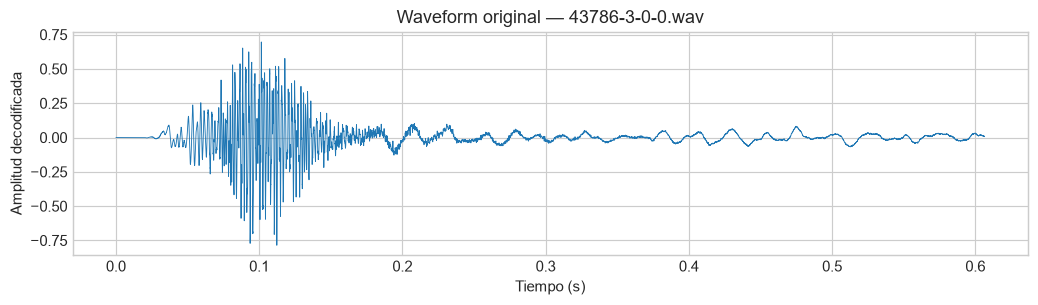

In [5]:
t = np.arange(y_mono.size) / sr
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, y_mono, linewidth=.6)
ax.set(xlabel='Tiempo (s)', ylabel='Amplitud decodificada', title=f'Waveform original — {audio_path.name}')
plt.tight_layout(); plt.show()

### Preguntas de reflexión — Parte A

1. El audio dura **0.607 s** y su sample rate original es **48000 Hz**.
2. La amplitud mono oscila entre **-0.7849 y 0.6967**. Está en la escala de audio float decodificado, pero el pico observado (0.8727) no prueba una normalización previa a un valor específico.
3. Tiene **2 canal(es)**. Trabajar en mono es adecuado para esta línea base de clasificación del sonido; se pierde ubicación estéreo y un promedio de canales en oposición de fase podría cancelar señal. Para localización espacial no elegiría mono sin evaluar esa pérdida.
4. `y` es **float32**. La codificación del archivo es PCM_16; convertir PCM a float produce valores cercanos a [−1,1], que es distinto de normalizar el pico de cada clip o de normalizar sonoridad.
5. Muchos valores sostenidos cerca de ±1 pueden indicar **clipping**, que deforma picos y agrega componentes espectrales. En este ejemplo la fracción de muestras en todos los canales con |y|≥0,999 es **0.0000%**; se revisa junto al waveform, no como diagnóstico infalible de clipping.

## Parte B — Estandarización del audio
### B.1 Mono, sample rate, duración y amplitud
Se guarda cuánto se recortó, cuánto se rellenó y el nivel original. Recortar con `trim` elimina extremos de baja energía, no silencios internos. La normalización de pico no es denoising ni normalización perceptual. El resampleo usa anti-aliasing y, a 16 kHz, no conserva contenido por encima de 8 kHz.

In [6]:
TARGET_SR, TARGET_DURATION = 16000, 3.0
TARGET_AMPLITUDE, TOP_DB = .99, 30.
N_FFT, HOP_LENGTH, N_MFCC = 2048, 512, 13

def fit_duration_amplitude(wave, sr=TARGET_SR, duration=TARGET_DURATION):
    wave = librosa.util.fix_length(np.asarray(wave, dtype=np.float32), size=int(sr*duration))
    peak = float(np.max(np.abs(wave)))
    if peak > 0:
        wave = wave * (TARGET_AMPLITUDE / peak)
    return wave.astype(np.float32)

def preprocess_audio(path, target_sr=TARGET_SR, target_duration=TARGET_DURATION, top_db=TOP_DB, return_info=False):
    wave, source_sr = load_audio(path, sr=None, mono=False)
    channel_count = 1 if wave.ndim == 1 else wave.shape[0]
    raw_duration = wave.shape[-1] / source_sr
    mono = wave.mean(axis=0) if wave.ndim > 1 else wave
    trimmed, interval = librosa.effects.trim(mono, top_db=top_db, frame_length=N_FFT, hop_length=HOP_LENGTH)
    resampled = librosa.resample(trimmed, orig_sr=source_sr, target_sr=target_sr, res_type='soxr_hq') if source_sr != target_sr else trimmed
    length = int(target_sr*target_duration)
    info = {'source_sr': int(source_sr), 'source_channels': channel_count, 'source_duration_sec': raw_duration,
        'source_peak': float(np.abs(wave).max()), 'source_rms': float(np.sqrt(np.mean(wave.astype(float)**2))),
        'source_clip_fraction': float((np.abs(wave) >= .999).mean()),
        'trim_removed_sec': (len(mono)-len(trimmed))/source_sr,
        'trim_start_sec': int(interval[0])/source_sr, 'trim_end_sec': int(interval[1])/source_sr,
        'available_duration_sec': len(resampled)/target_sr,
        'pad_fraction': max(0, length-len(resampled))/length,
        'crop_fraction': max(0, len(resampled)-length)/max(1, len(resampled))}
    standardized = fit_duration_amplitude(resampled, target_sr, target_duration)
    return (standardized, target_sr, info) if return_info else (standardized, target_sr)

y_std, sr_std, example_info = preprocess_audio(audio_path, return_info=True)
assert y_std.shape == (48000,) and sr_std == 16000
assert y_std.dtype == np.float32 and np.isfinite(y_std).all() and np.abs(y_std).max() <= 1
print('Forma estandarizada:', y_std.shape, '| sr:', sr_std, '| pico:', float(np.abs(y_std).max()))
print(json.dumps(example_info, indent=2))
sf.write(OUTPUTS['audio'] / 'ejemplo_estandarizado.wav', y_std, sr_std, subtype='PCM_16')

Forma estandarizada: (48000,) | sr: 16000 | pico: 0.9899999499320984
{
  "source_sr": 48000,
  "source_channels": 2,
  "source_duration_sec": 0.6065,
  "source_peak": 0.8726806640625,
  "source_rms": 0.10238178840949662,
  "source_clip_fraction": 0.0,
  "trim_removed_sec": 0.021333333333333333,
  "trim_start_sec": 0.021333333333333333,
  "trim_end_sec": 0.6065,
  "available_duration_sec": 0.5851875,
  "pad_fraction": 0.8049375,
  "crop_fraction": 0.0
}


### B.2 Waveform original vs estandarizado

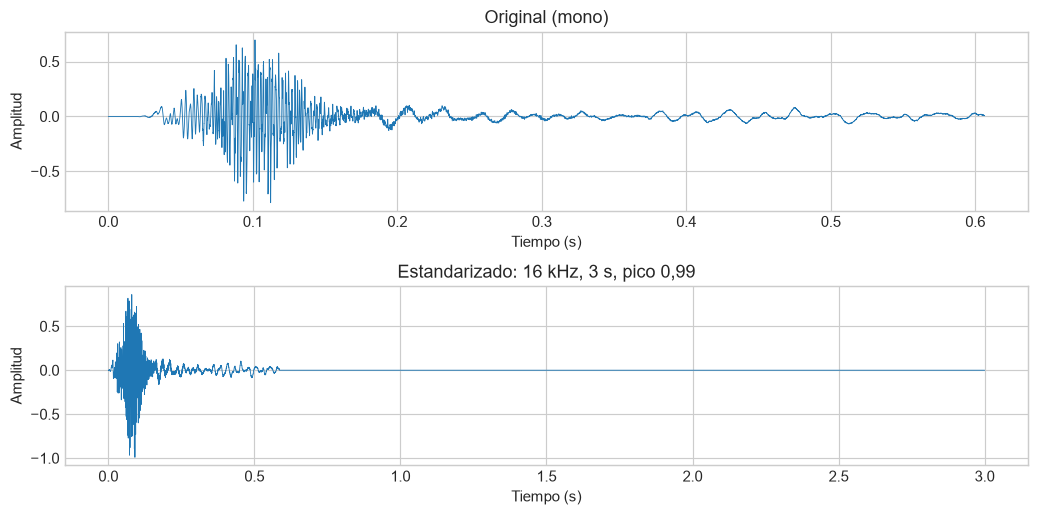

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5))
for axis, wave, rate, title in zip(axes, [y_mono, y_std], [sr, sr_std], ['Original (mono)', 'Estandarizado: 16 kHz, 3 s, pico 0,99']):
    axis.plot(np.arange(len(wave))/rate, wave, linewidth=.6)
    axis.set(xlabel='Tiempo (s)', ylabel='Amplitud', title=title)
plt.tight_layout(); plt.show()

### Preguntas de reflexión — Parte B

1. A **16 kHz**, 3 s son **48000 muestras**, frente a 132300 a 44,1 kHz: se usa el 36.3% de las muestras a igual duración, canales y dtype. El límite de Nyquist baja a 8 kHz; puede ser suficiente para una línea base, pero se descarta información de sonidos urbanos agudos que podría servir.
2. `top_db=30` quitó **0.021 s** de los extremos. El criterio es energía relativa al pico por ventanas; no certifica silencio absoluto y puede quitar eventos débiles. En este ejemplo se revisa el waveform junto a los tiempos guardados, sin asumir que todo lo removido era ruido.
3. Llevar el pico a **0,99** unifica la escala y deja un pequeño margen antes de ±1. No elimina ruido y puede amplificar grabaciones muy suaves; por eso se conservan el RMS y clipping originales.
4. Aumentar la duración a **5 s** produciría **80000 muestras**, 1,67 veces las de 3 s y 320000 bytes en mono float32 sin compresión. También crecerían los frames y el costo de procesar el lote.
5. Recortar siempre el centro no es necesariamente mejor: puede conservar un evento central, pero perder un ladrido o disparo que ocurre al inicio. UrbanSound8K contiene eventos y texturas distintas. Se usa el inicio después del trim para tener una regla reproducible; para producción compararía ventanas múltiples y agregación antes de decidir.

## Parte C — Espectrogramas y ruido
### C.1 Espectrograma de potencia
Se grafica `|STFT|²` y se convierte con `power_to_db`, acorde al título de la consigna. Las comparaciones de ruido/filtrado comparten referencia y escala de color. Los dB son relativos a una potencia STFT de referencia, no mediciones de presión sonora ni una calibración de sonoridad.

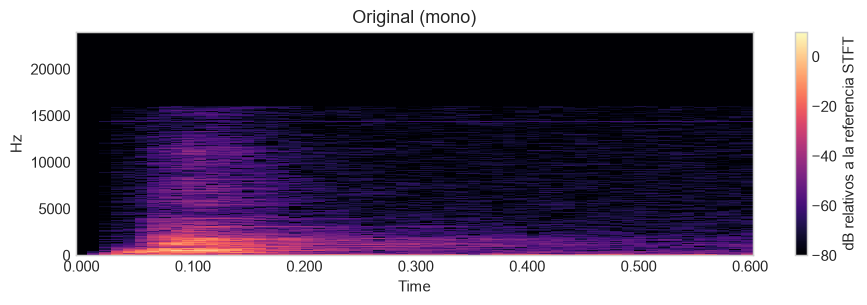

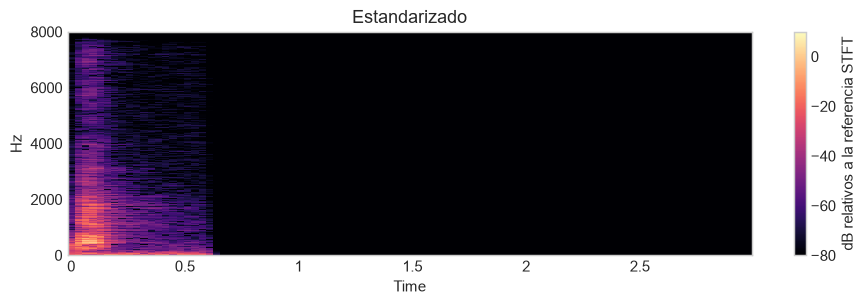

In [8]:
REFERENCE_POWER = float(np.abs(librosa.stft(y_std, n_fft=N_FFT, hop_length=HOP_LENGTH)).max()**2)

def plot_spectrogram(wave, rate, title='', reference_power=None):
    power = np.abs(librosa.stft(wave, n_fft=N_FFT, hop_length=HOP_LENGTH))**2
    reference = max(1e-12, REFERENCE_POWER if reference_power is None else reference_power)
    db = librosa.power_to_db(power, ref=reference, top_db=None)
    fig, ax = plt.subplots(figsize=(9, 3))
    image = librosa.display.specshow(db, sr=rate, hop_length=HOP_LENGTH, x_axis='time', y_axis='hz', ax=ax, vmin=-80, vmax=10)
    ax.set_title(title)
    fig.colorbar(image, ax=ax, label='dB relativos a la referencia STFT')
    plt.tight_layout(); plt.show()
    return db

S_db_orig = plot_spectrogram(y_mono, sr, 'Original (mono)')
S_db_std = plot_spectrogram(y_std, sr_std, 'Estandarizado')

### C.2 Ruido y SNR
El SNR se define respecto de la **señal digital antes de añadir ruido**, que no es una grabación libre de todo ruido ambiental. Se ajusta la potencia del ruido aleatorio para alcanzar el SNR solicitado y se mide el valor realizado. Se mantienen floats sin clippear para no alterar artificialmente ese experimento.

SNR solicitado/medido: 10.0 10.0
Pico float con ruido (puede superar 1): 1.0110059976577759


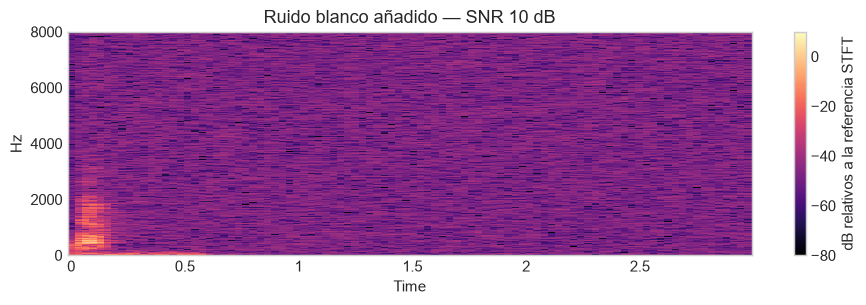

In [9]:
def add_white_noise(wave, snr_db, seed=SEED):
    wave = np.asarray(wave, dtype=np.float64)
    signal_power = float(np.mean(wave**2))
    if signal_power == 0:
        return wave.astype(np.float32)
    noise = np.random.default_rng(seed).normal(size=wave.shape)
    noise *= np.sqrt(signal_power / (10**(snr_db/10) * np.mean(noise**2)))
    return (wave+noise).astype(np.float32)

def snr_against_reference(reference, candidate):
    signal_power = float(np.mean(np.asarray(reference, dtype=float)**2))
    error_power = float(np.mean((np.asarray(candidate, dtype=float)-reference)**2))
    return float(10*np.log10(max(signal_power, 1e-20)/max(error_power, 1e-20)))

snr_target_db = 10.
y_noisy = add_white_noise(y_std, snr_target_db)
snr_measured = snr_against_reference(y_std, y_noisy)
print('SNR solicitado/medido:', snr_target_db, round(snr_measured, 4))
print('Pico float con ruido (puede superar 1):', float(np.abs(y_noisy).max()))
assert abs(snr_measured-snr_target_db) < .001
S_db_noisy = plot_spectrogram(y_noisy, sr_std, 'Ruido blanco añadido — SNR 10 dB')

### C.3 High-pass para ruido grave
Se usa Butterworth de orden 4 en secciones de segundo orden (SOS). El filtrado adelante/atrás evita desfase para las comparaciones offline. No es una implementación causal de streaming y afecta también las bajas frecuencias útiles. Un high-pass no elimina ruido blanco de todo el espectro.

Fracción de potencia <80 Hz: 0.06421 → 0.00062
SNR contra la referencia después de HP: 7.84


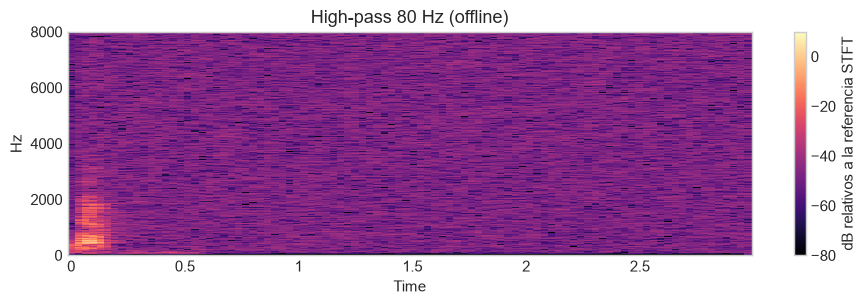

In [10]:
def highpass_filter(wave, rate, cutoff_hz=80., order=4):
    sos = signal.butter(order, cutoff_hz, btype='highpass', fs=rate, output='sos')
    return signal.sosfiltfilt(sos, wave).astype(np.float32)

def low_frequency_fraction(wave, rate, cutoff=80.):
    frequencies, psd = signal.welch(wave, fs=rate, nperseg=min(2048, len(wave)))
    return float(psd[frequencies < cutoff].sum()/max(float(psd.sum()), 1e-20))

y_hp = highpass_filter(y_noisy, sr_std)
low_before = low_frequency_fraction(y_noisy, sr_std)
low_after = low_frequency_fraction(y_hp, sr_std)
print('Fracción de potencia <80 Hz:', round(low_before, 5), '→', round(low_after, 5))
print('SNR contra la referencia después de HP:', round(snr_against_reference(y_std, y_hp), 3))
S_db_hp = plot_spectrogram(y_hp, sr_std, 'High-pass 80 Hz (offline)')

def audio_comparison(waves, rate):
    common_gain = .99/max(1., max(float(np.abs(w).max()) for w in waves.values()))
    panels = []
    for label, wave in waves.items():
        buffer = io.BytesIO()
        sf.write(buffer, wave*common_gain, rate, format='WAV', subtype='PCM_16')
        panels.append(f'<p><strong>{label}</strong><br><audio controls src="data:audio/wav;base64,{base64.b64encode(buffer.getvalue()).decode()}"></audio></p>')
    return HTML(f'<p>Ganancia común de reproducción: {common_gain:.4f}; no se normaliza cada versión por separado.</p>'+''.join(panels))

audio_comparison({'Referencia estandarizada': y_std, 'Ruido blanco 10 dB': y_noisy, 'High-pass 80 Hz': y_hp}, sr_std)

### Preguntas de reflexión — Parte C

1. El ruido blanco aparece como un **fondo amplio de energía repartida por frecuencias y tiempo**, frente a la estructura localizada del sonido. A bajo SNR puede ocultar detalles; las figuras usan la misma referencia de color.
2. El high-pass atenúa frecuencias **por debajo de 80 Hz**, con transición gradual, no una pared ideal. La fracción de potencia en esa banda pasa de 6.421% a 0.062%. El efecto sobre contenido útil depende de la clase: motores y otros sonidos graves pueden perder información. El SNR debe medirse, no suponerse mejor por filtrar.
3. Para un **hum estrecho conocido a 50 o 60 Hz**, elegiría un notch centrado en la frecuencia detectada, para conservar otras bajas frecuencias. Un high-pass alrededor de 80 Hz elimina una banda más amplia y solo lo elegiría si esa pérdida es aceptable. El extra F.2 compara ambas estrategias sobre un hum controlado a 50 Hz.
4. A 16 kHz, `n_fft=2048` cubre **128 ms**, y `hop_length=512` avanza **32 ms**; la separación de bins es **7,8125 Hz**. Para mayor resolución temporal usaría **1024/256**: ventana de 64 ms, avance de 16 ms y bins de 15,625 Hz. Se pierde resolución frecuencial. Reducir solo el hop densifica mediciones, pero no acorta la ventana de análisis.

## Parte D — Extracción de MFCC y CSV
### D.1 MFCC agregados
Se usan 13 coeficientes, con media y STD por clip, más RMS y ZCR: 28 features. Los parámetros STFT son explícitos para todas las features. `mfcc_1` corresponde al coeficiente de orden **0** de librosa, porque el nombre exportado comienza en 1. Agregar por media/STD pierde el orden temporal de los eventos. Los frames de padding se incluyen en la línea base fija de 3 s y se informa su fracción.

In [11]:
def extract_mfcc_features(wave, rate, n_mfcc=N_MFCC):
    mfcc = librosa.feature.mfcc(y=wave, sr=rate, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=40, fmin=20., fmax=rate/2)
    features = {}
    for i in range(n_mfcc):
        features[f'mfcc_{i+1}_mean'] = float(mfcc[i].mean())
        features[f'mfcc_{i+1}_std'] = float(mfcc[i].std())
    features['rms_mean'] = float(librosa.feature.rms(y=wave, frame_length=N_FFT, hop_length=HOP_LENGTH).mean())
    features['zcr_mean'] = float(librosa.feature.zero_crossing_rate(y=wave, frame_length=N_FFT, hop_length=HOP_LENGTH).mean())
    return features

feature_columns = [name for i in range(1, 14) for name in [f'mfcc_{i}_mean', f'mfcc_{i}_std']] + ['rms_mean', 'zcr_mean']
feats_example = extract_mfcc_features(y_std, sr_std)
assert len(feats_example) == 28 and np.isfinite(list(feats_example.values())).all()
print('Cantidad de features:', len(feats_example))
pd.Series(feats_example).head(8)

Cantidad de features: 28


mfcc_1_mean   -295.849884
mfcc_1_std      82.702271
mfcc_2_mean     15.268029
mfcc_2_std      29.952187
mfcc_3_mean     -1.130331
mfcc_3_std       6.917962
mfcc_4_mean      0.902610
mfcc_4_std       3.655546
dtype: float64

### D.2 Pipeline sobre todos los audios del núcleo
Se procesan 100 clips de forma balanceada por clase y fold, en lugar de tomar los primeros 100 nombres del fold 1. Los errores se exportan con archivo y tipo; no se omiten silenciosamente. El cache en memoria permite reutilizar procesamiento y métricas en el QA de 200.

In [12]:
processed_cache, feature_cache, info_cache, errors = {}, {}, {}, []

def process_cached(path):
    key = path.relative_to(RAW_DIR).as_posix()
    if key not in processed_cache:
        wave, rate, info = preprocess_audio(path, return_info=True)
        processed_cache[key] = wave
        info_cache[key] = info
        feature_cache[key] = extract_mfcc_features(wave, rate)
    return processed_cache[key], feature_cache[key], info_cache[key]

rows = []
for path in core_files:
    try:
        wave, features, info = process_cached(path)
        rows.append({**features, 'filename': path.name, 'relative_path': path.relative_to(RAW_DIR).as_posix(),
            'sr': TARGET_SR, 'duration_sec': len(wave)/TARGET_SR, 'mfcc_frames': 1+len(wave)//HOP_LENGTH, **info})
    except Exception as error:
        errors.append({'filename': path.name, 'error_type': type(error).__name__})
df_features = pd.DataFrame(rows)
pd.DataFrame(errors, columns=['filename', 'error_type']).to_csv(OUTPUTS['metrics'] / 'errores_procesamiento.csv', index=False)
assert len(df_features) == 100 and not errors
assert np.isfinite(df_features[feature_columns].to_numpy()).all()
print('Procesados:', len(df_features), '| errores:', len(errors))
df_features.head()

Procesados: 100 | errores: 0


,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,mfcc_4_std,...,source_rms,source_clip_fraction,trim_removed_sec,trim_start_sec,trim_end_sec,available_duration_sec,pad_fraction,crop_fraction
0,-4.478273,3.743196,65.740028,3.283019,9.990783,2.491182,2.600352,2.142807,...,0.036248,0.0,0.000000,0.000000,4.000000,4.000000,0.000000,0.25
1,-180.386551,163.839493,13.324710,16.547606,-3.554583,4.603974,11.148006,11.360214,...,0.066245,0.0,0.000000,0.000000,1.440000,1.440000,0.520000,0.00
2,-184.084167,105.217903,26.078062,22.083134,0.449039,12.668048,13.226108,9.602921,...,0.033270,0.0,0.469274,0.000000,2.240726,2.240750,0.253083,0.00
3,-295.849884,82.702271,15.268029,29.952187,-1.130331,6.917962,0.902610,3.655546,...,0.102382,0.0,0.021333,0.021333,0.606500,0.585187,0.804937,0.00
4,-166.789047,192.437576,18.926889,17.081045,-10.553889,10.956515,9.594290,9.173089,...,0.089856,0.0,0.000000,0.000000,1.700000,1.700000,0.433333,0.00


### D.3 Guardar CSV

In [13]:
out_csv = OUTPUTS['features'] / 'audio_mfcc_features.csv'
df_features.to_csv(out_csv, index=False)
parameters = {'seed': SEED, 'sample_rate': TARGET_SR, 'duration_sec': TARGET_DURATION, 'mono': True,
    'peak': TARGET_AMPLITUDE, 'trim_top_db': TOP_DB, 'n_fft': N_FFT, 'hop_length': HOP_LENGTH,
    'n_mfcc': N_MFCC, 'n_mels': 40, 'highpass_hz': 80., 'normalization': 'peak; not loudness'}
(OUTPUTS['metrics'] / 'parametros.json').write_text(json.dumps(parameters, indent=2), encoding='utf-8')
print('CSV:', out_csv, '| forma:', df_features.shape, '| features numéricas para ML:', len(feature_columns))

CSV: outputs\features\audio_mfcc_features.csv | forma: (100, 45) | features numéricas para ML: 28


### Preguntas de reflexión — Parte D

1. **13 MFCC** es una línea base compacta que resume la envolvente espectral. Más coeficientes agregan detalle y dimensiones; con solo 100 clips aumenta el riesgo de ajustar ruido o particularidades de grabación. No se eligió 13 por una optimización sobre el test.
2. `mfcc_1_mean` es el promedio temporal del **C0**, relacionado con el nivel de log-energía de las bandas mel. Está más ligado a energía global/envolvente que a textura fina, pero **no es una medida exacta de potencia ni sonoridad**: depende del espectro, banco mel y escala logarítmica. RMS mide otra propiedad y se conserva por separado.
3. Las etiquetas provienen de **`UrbanSound8K.csv`: `class` y `classID`**, unidas por nombre de archivo con validación uno-a-uno. Se conservan `fold` y `fsID` para separar grabaciones. Como QA agregaría fracción de clipping original, padding y un proxy de ruido; no se afirma conocer el SNR real sin referencia.
4. Usaría **StandardScaler**, ajustado solo con entrenamiento dentro de un Pipeline: MFCC, RMS y ZCR tienen escalas distintas. No se escalan los datos completos antes de separar ni se usan nombre, clase, fold o identificador de grabación como features predictoras.

## Parte E — Exploraciones avanzadas
### E.1 Métricas espectrales adicionales

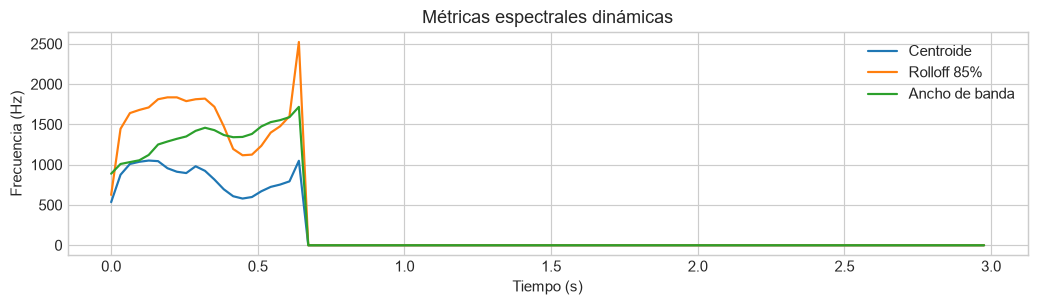

In [14]:
centroid = librosa.feature.spectral_centroid(y=y_std, sr=sr_std, n_fft=N_FFT, hop_length=HOP_LENGTH)[0]
rolloff = librosa.feature.spectral_rolloff(y=y_std, sr=sr_std, n_fft=N_FFT, hop_length=HOP_LENGTH, roll_percent=.85)[0]
bandwidth = librosa.feature.spectral_bandwidth(y=y_std, sr=sr_std, n_fft=N_FFT, hop_length=HOP_LENGTH)[0]
times = librosa.frames_to_time(np.arange(len(centroid)), sr=sr_std, hop_length=HOP_LENGTH)
fig, ax = plt.subplots(figsize=(10, 3))
for values, label in [(centroid, 'Centroide'), (rolloff, 'Rolloff 85%'), (bandwidth, 'Ancho de banda')]:
    ax.plot(times, values, label=label)
ax.set(xlabel='Tiempo (s)', ylabel='Frecuencia (Hz)', title='Métricas espectrales dinámicas')
ax.legend(); plt.tight_layout(); plt.show()
pd.DataFrame({'time_sec': times, 'centroid_hz': centroid, 'rolloff_hz': rolloff, 'bandwidth_hz': bandwidth}).to_csv(OUTPUTS['features'] / 'metricas_espectrales_ejemplo.csv', index=False)

El centroide resume el “centro de masa” frecuencial; el rolloff indica hasta dónde se acumula el 85% de la energía; el ancho de banda mide dispersión alrededor del centroide. Son descriptores, no etiquetas de ruido: sonidos válidos distintos pueden tener valores muy diferentes.

### E.2 Características del dataset y modelo rápido
Se usa la clase oficial, sin etiquetar por nombre inventado. Se muestran los folds completos y los WAV descargados por separado. El modelo utiliza el núcleo de 100 clips: folds 1–8 para entrenamiento/validación, folds 9–10 reservados para test. La validación agrupa por fold y se verifica que no se comparta `fsID` entre train y test. Este subconjunto no sustituye la evaluación estándar sobre el dataset completo.

Train: 80 | test reservado: 20 | grabaciones compartidas: 0
 fold_validacion  accuracy  macro_f1
               1      0.50    0.4667
               2      0.55    0.5100
               3      0.50    0.4883
               4      0.55    0.5000
El test se evalúa después de fijar la receta de aumento de E.3.


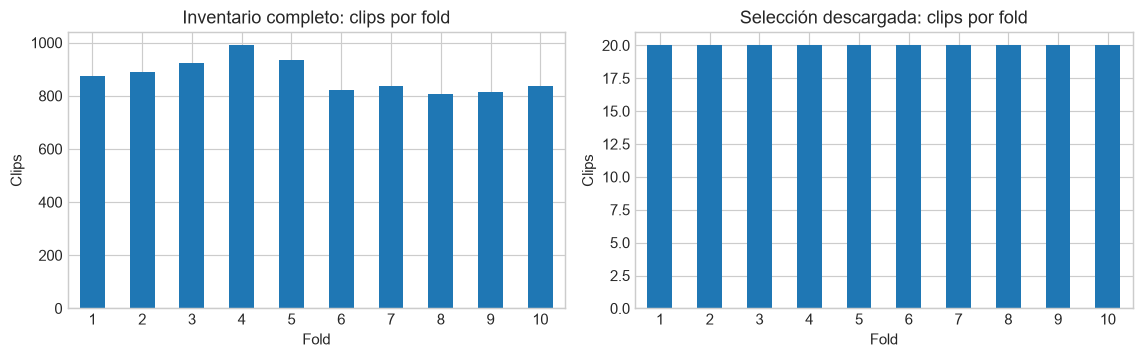

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
metadata.fold.value_counts().sort_index().plot.bar(ax=axes[0], title='Inventario completo: clips por fold')
selection.fold.value_counts().sort_index().plot.bar(ax=axes[1], title='Selección descargada: clips por fold')
for axis in axes:
    axis.set(xlabel='Fold', ylabel='Clips'); axis.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
labels = metadata[['slice_file_name', 'fsID', 'fold', 'classID', 'class']].rename(columns={'slice_file_name': 'filename', 'class': 'class_name'})
assert labels.filename.is_unique
df_labeled = df_features.merge(labels, on='filename', validate='one_to_one')
assert len(df_labeled) == 100 and df_labeled.classID.notna().all()
df_labeled.to_csv(OUTPUTS['features'] / 'audio_mfcc_features_etiquetados.csv', index=False)
train = df_labeled.loc[df_labeled.fold <= 8].copy()
test = df_labeled.loc[df_labeled.fold >= 9].copy()
assert not set(train.fsID) & set(test.fsID)
assert not set(train.filename) & set(test.filename)
class_names = metadata[['classID', 'class']].drop_duplicates().sort_values('classID')['class'].tolist()
baseline_model = make_pipeline(StandardScaler(), LogisticRegression(C=1., max_iter=2000, random_state=SEED))
cv = GroupKFold(n_splits=4)
cv_scores = cross_validate(baseline_model, train[feature_columns], train.classID, groups=train.fold,
    cv=cv, scoring={'accuracy': 'accuracy', 'macro_f1': 'f1_macro'}, n_jobs=1)
cv_table = pd.DataFrame({'fold_validacion': range(1, 5), 'accuracy': cv_scores['test_accuracy'], 'macro_f1': cv_scores['test_macro_f1']})
cv_table.to_csv(OUTPUTS['metrics'] / 'modelo_validacion.csv', index=False)
print('Train:', len(train), '| test reservado:', len(test), '| grabaciones compartidas: 0')
print(cv_table.round(4).to_string(index=False))
print('El test se evalúa después de fijar la receta de aumento de E.3.')

### E.3 Augmentación básica
Se aplica pitch shift +2 semitonos y time stretch 0,9× a **cada clip de entrenamiento**. Después se ajustan longitud y pico para volver al contrato 16 kHz/3 s/0,99. Se conservan identificadores de origen y se exportan los MFCC de cada variante. Nunca se aumentan clips del test para entrenar; el mismo origen y todas sus variantes pertenecen al mismo lado de la separación.

Un cambio de pitch o velocidad no es necesariamente neutro para todas las clases. La receta se fija antes del test, y se compara como exploración con el mismo modelo e hiperparámetros; no se presenta una mejora garantizada.

Medias de features según variante:
               mfcc_1_mean  mfcc_1_std  mfcc_2_mean  rms_mean  zcr_mean
augmentation                                                          
original        -102.0043     58.3874      41.0410    0.1521    0.1134
pitch_plus2      -96.8279     55.1489      39.2656    0.1551    0.1212
stretch_09       -96.0267     55.0822      42.9681    0.1563    0.1126
      model  accuracy_test  macro_f1_test  n_test
      Dummy            0.1         0.0182      20
   Original            0.6         0.5567      20
Con aumento            0.5         0.4100      20
                  precision    recall  f1-score   support

 air_conditioner       0.00      0.00      0.00         2
        car_horn       1.00      0.50      0.67         2
children_playing       0.25      0.50      0.33         2
        dog_bark       1.00      0.50      0.67         2
        drilling       0.67      1.00      0.80         2
   engine_idling       1.00      1.00      1.00         2
  

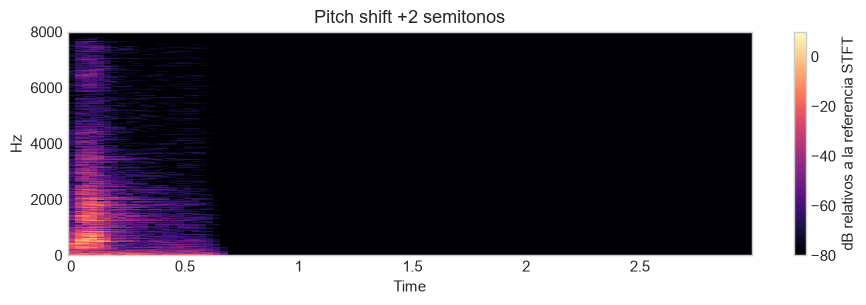

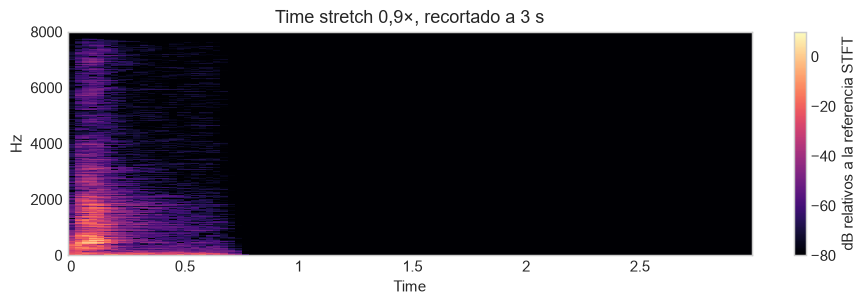

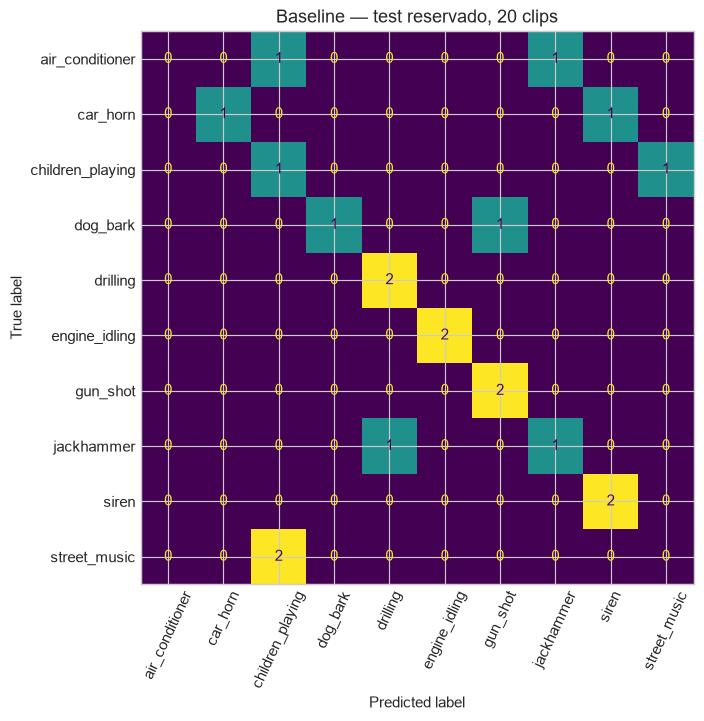

In [16]:
def augment_pitch_shift(wave, rate, steps=2):
    return fit_duration_amplitude(librosa.effects.pitch_shift(wave, sr=rate, n_steps=steps), rate)

def augment_time_stretch(wave, rate, speed=.9):
    return fit_duration_amplitude(librosa.effects.time_stretch(wave, rate=speed), rate)

y_pitch = augment_pitch_shift(y_std, sr_std)
y_time = augment_time_stretch(y_std, sr_std)
plot_spectrogram(y_pitch, sr_std, 'Pitch shift +2 semitonos')
plot_spectrogram(y_time, sr_std, 'Time stretch 0,9×, recortado a 3 s')
augmentation_rows = []
for row in train.itertuples():
    key = row.relative_path
    wave = processed_cache[key]
    for name, augmented in [('pitch_plus2', augment_pitch_shift(wave, TARGET_SR)), ('stretch_09', augment_time_stretch(wave, TARGET_SR))]:
        assert augmented.shape == (48000,) and np.abs(augmented).max() <= 1
        augmentation_rows.append({**extract_mfcc_features(augmented, TARGET_SR), 'filename': row.filename,
            'source_id': row.fsID, 'fold': row.fold, 'classID': row.classID, 'augmentation': name})
augmented_features = pd.DataFrame(augmentation_rows)
original_export = df_labeled[feature_columns+['filename', 'fsID', 'fold', 'classID']].rename(columns={'fsID': 'source_id'}).copy()
original_export['augmentation'] = 'original'
df_augmented = pd.concat([original_export, augmented_features], ignore_index=True)
df_augmented.to_csv(OUTPUTS['features'] / 'audio_mfcc_features_aumentados.csv', index=False)
assert len(augmentation_rows) == 160 and len(df_augmented) == 260
assert not set(augmented_features.source_id) & set(test.fsID)
augmentation_summary = df_augmented.groupby('augmentation')[['mfcc_1_mean', 'mfcc_1_std', 'mfcc_2_mean', 'rms_mean', 'zcr_mean']].mean()
print('Medias de features según variante:\n', augmentation_summary.round(4).to_string())
baseline_model.fit(train[feature_columns], train.classID)
train_augmented = pd.concat([train[feature_columns+['classID']], augmented_features[feature_columns+['classID']]], ignore_index=True)
augmented_model = make_pipeline(StandardScaler(), LogisticRegression(C=1., max_iter=2000, random_state=SEED)).fit(train_augmented[feature_columns], train_augmented.classID)
dummy = DummyClassifier(strategy='most_frequent').fit(train[feature_columns], train.classID)
test_rows, predictions = [], {}
for name, model in [('Dummy', dummy), ('Original', baseline_model), ('Con aumento', augmented_model)]:
    predicted = model.predict(test[feature_columns])
    predictions[name] = predicted
    test_rows.append({'model': name, 'accuracy_test': accuracy_score(test.classID, predicted), 'macro_f1_test': f1_score(test.classID, predicted, average='macro', zero_division=0), 'n_test': len(test)})
model_results = pd.DataFrame(test_rows)
model_results.to_csv(OUTPUTS['metrics'] / 'modelo_test.csv', index=False)
pd.DataFrame({'filename': test.filename, 'true_class': test.classID, 'pred_original': predictions['Original'], 'pred_augmented': predictions['Con aumento']}).to_csv(OUTPUTS['metrics'] / 'predicciones_test.csv', index=False)
print(model_results.round(4).to_string(index=False))
print(classification_report(test.classID, predictions['Original'], labels=list(range(10)), target_names=class_names, zero_division=0))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(test.classID, predictions['Original'], labels=list(range(10)), display_labels=class_names, xticks_rotation=65, ax=ax, colorbar=False)
ax.set_title('Baseline — test reservado, 20 clips')
plt.tight_layout(); plt.show()

**Resultado del modelo y aumento:** el baseline original obtiene accuracy 60.0% y macro-F1 0.557; con aumento, 50.0% y 0.410. El test tiene solo **20 clips**: un acierto modifica accuracy en **5 puntos porcentuales**. No alcanza para afirmar superioridad estadística ni extrapolar al dataset completo. Se fijaron features y recetas antes del test; la tabla de aumentos muestra cambios en medias y STD de los coeficientes, no garantiza conservar toda la información de clase.

## F) Desafíos opcionales
### F.1) Sensibilidad al ruido y extensión de varianza
Se mantiene la misma realización de ruido y se modifica solamente su amplitud. Esto permite atribuir las diferencias al SNR. Se calculan los descriptores sobre cada señal contaminada, sin recortar los picos que superen 1 en memoria.

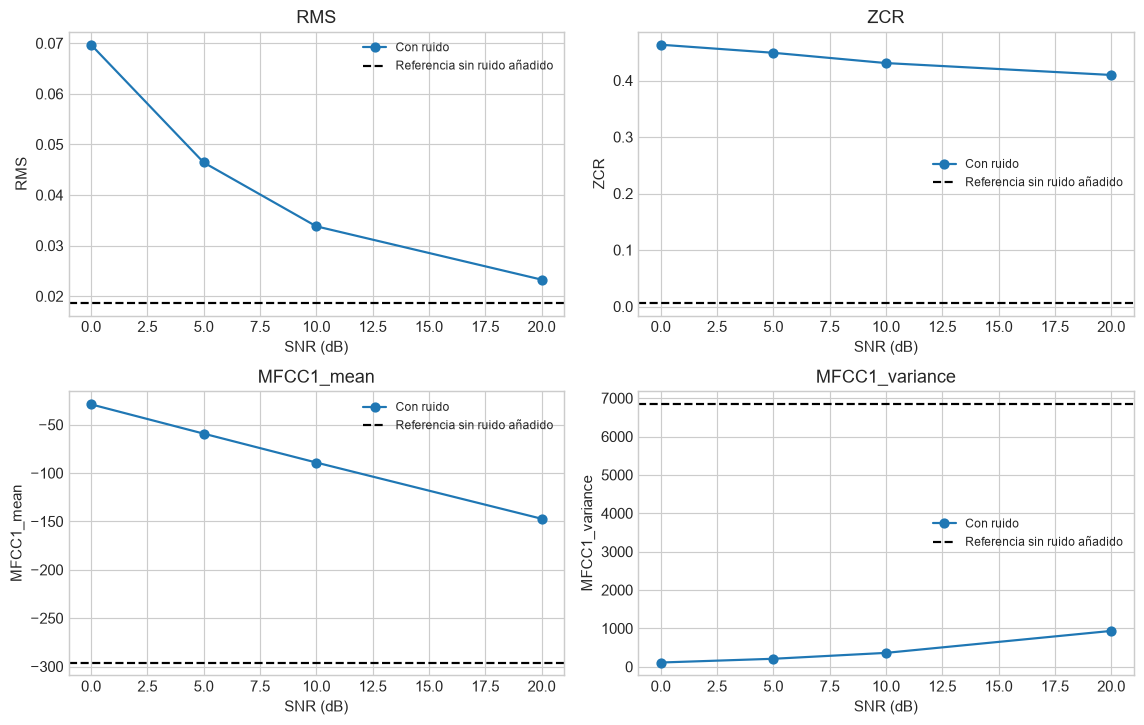

,SNR_requested_dB,SNR_measured_dB,RMS,ZCR,MFCC1_mean,MFCC1_std,MFCC1_variance
0,0,0.0,0.06972,0.46333,-28.87468,10.56656,111.65223
1,5,5.0,0.04644,0.44904,-59.16769,14.46364,209.19686
2,10,10.0,0.03382,0.43087,-89.06474,19.04890,362.86047
3,20,20.0,0.02328,0.40980,-147.17010,30.58180,935.24675


In [17]:
snr_rows = []
for snr_db in [0, 5, 10, 20]:
    noisy = add_white_noise(y_std, snr_db, seed=SEED)
    descriptors = extract_mfcc_features(noisy, TARGET_SR)
    snr_rows.append({'SNR_requested_dB': snr_db, 'SNR_measured_dB': snr_against_reference(y_std, noisy),
        'RMS': descriptors['rms_mean'], 'ZCR': descriptors['zcr_mean'],
        'MFCC1_mean': descriptors['mfcc_1_mean'], 'MFCC1_std': descriptors['mfcc_1_std'],
        'MFCC1_variance': descriptors['mfcc_1_std'] ** 2})
snr_table = pd.DataFrame(snr_rows)
assert np.allclose(snr_table.SNR_requested_dB, snr_table.SNR_measured_dB, atol=0.001)
snr_table.to_csv(OUTPUTS['metrics'] / 'sensibilidad_snr.csv', index=False)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
clean_features = extract_mfcc_features(y_std, TARGET_SR)
for ax, column, baseline in zip(axes.flat, ['RMS', 'ZCR', 'MFCC1_mean', 'MFCC1_variance'],
        [clean_features['rms_mean'], clean_features['zcr_mean'], clean_features['mfcc_1_mean'], clean_features['mfcc_1_std']**2]):
    ax.plot(snr_table.SNR_requested_dB, snr_table[column], 'o-', label='Con ruido')
    ax.axhline(baseline, color='black', ls='--', label='Referencia sin ruido añadido')
    ax.set(xlabel='SNR (dB)', ylabel=column, title=column)
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
snr_table.round(5)

**Análisis:** al bajar SNR, el ruido aumenta su potencia respecto del audio de referencia; el RMS y los cruces por cero suelen aumentar. Los MFCC también cambian porque cambia el espectro log-mel. La media del primer coeficiente está vinculada a la energía logarítmica global y su varianza describe cambios entre ventanas: no tienen por qué variar de forma monótona. Una señal puede conservar su volumen y perder su estructura espectral, por lo que RMS por sí solo no mide calidad ni robustez de un clasificador.

### F.2) Benchmark de pipelines: original, pasa-altos y pasa-altos + trim
Se evalúan las salidas **efectivas** de cada pipeline. Se añade una comparación con notch de 50 Hz para separar ruido blanco y zumbido. El SNR se calcula contra la misma referencia, recortada con los mismos índices si el trim cambia la longitud. No se vuelve a normalizar entre variantes: eso alteraría artificialmente la comparación de amplitudes.

       noise      pipeline  duration_sec  SNR_reference_dB  energy_fraction_below_80Hz  rms_mean  zcr_mean  mfcc_1_mean
      blanco           raw         3.000          10.00000                     0.06421   0.03382   0.43087    -89.06474
      blanco      highpass         3.000           7.83960                     0.00062   0.03091   0.46853    -89.78677
      blanco highpass_trim         3.000           7.83960                     0.00062   0.03091   0.46853    -89.78677
      blanco    notch_50Hz         3.000           9.98408                     0.06187   0.03377   0.43079    -89.07606
zumbido_50Hz           raw         3.000          10.00000                     0.15929   0.03395   0.01093   -288.87653
zumbido_50Hz      highpass         3.000          11.83561                     0.00073   0.01517   0.02143   -293.47705
zumbido_50Hz highpass_trim         0.512          12.05784                     0.00065   0.08093   0.08373   -138.78600
zumbido_50Hz    notch_50Hz         3.000

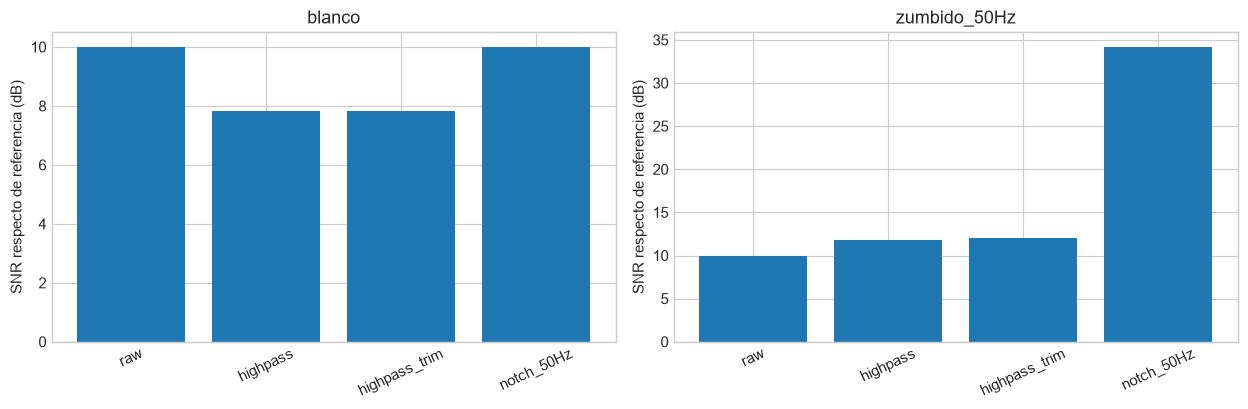

In [18]:
def notch50(y, sr):
    b, a = signal.iirnotch(50, Q=30, fs=sr)
    return signal.filtfilt(b, a, y).astype(np.float32)

hum_unit = np.sin(2*np.pi*50*np.arange(len(y_std))/TARGET_SR)
hum = hum_unit * (np.sqrt(np.mean(y_std**2))/np.sqrt(np.mean(hum_unit**2)) / 10**(10/20))
y_hum = (y_std + hum).astype(np.float32)
benchmark_rows = []
benchmark_waves = {}
for noise_name, contaminated in [('blanco', y_noisy), ('zumbido_50Hz', y_hum)]:
    hp = highpass_filter(contaminated, TARGET_SR)
    hp_trim, interval = librosa.effects.trim(hp, top_db=TOP_DB, frame_length=N_FFT, hop_length=HOP_LENGTH)
    variants = {'raw': (contaminated, 0, len(contaminated)), 'highpass': (hp, 0, len(hp)),
        'highpass_trim': (hp_trim, int(interval[0]), int(interval[1])),
        'notch_50Hz': (notch50(contaminated, TARGET_SR), 0, len(contaminated))}
    for pipeline_name, (y_out, start, end) in variants.items():
        reference = y_std[start:end]
        assert len(y_out) == len(reference) and len(y_out) > N_FFT
        descriptors = extract_mfcc_features(y_out, TARGET_SR)
        benchmark_rows.append({'noise': noise_name, 'pipeline': pipeline_name,
            'duration_sec': len(y_out)/TARGET_SR, 'SNR_reference_dB': snr_against_reference(reference, y_out),
            'energy_fraction_below_80Hz': low_frequency_fraction(y_out, TARGET_SR), **descriptors})
        benchmark_waves[(noise_name, pipeline_name)] = y_out
benchmark = pd.DataFrame(benchmark_rows)
assert benchmark.loc[benchmark.noise.eq('blanco'), 'rms_mean'].nunique() > 1
benchmark.to_csv(OUTPUTS['metrics'] / 'benchmark_pipelines.csv', index=False)
print(benchmark[['noise', 'pipeline', 'duration_sec', 'SNR_reference_dB', 'energy_fraction_below_80Hz', 'rms_mean', 'zcr_mean', 'mfcc_1_mean']].round(5).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, noise_name in zip(axes, ['blanco', 'zumbido_50Hz']):
    subset = benchmark.loc[benchmark.noise.eq(noise_name)]
    ax.bar(subset.pipeline, subset.SNR_reference_dB)
    ax.set(title=noise_name, ylabel='SNR respecto de referencia (dB)')
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()
audio_comparison({'Zumbido añadido': y_hum, 'Pasa-altos': benchmark_waves[('zumbido_50Hz', 'highpass')],
    'Notch 50 Hz': benchmark_waves[('zumbido_50Hz', 'notch_50Hz')]}, TARGET_SR)

**Elección del pipeline:** el pasa-altos reduce la fracción de energía por debajo de 80 Hz, pero eso no demuestra por sí solo que preserve el sonido útil. En este ensayo con ruido blanco, raw tiene SNR 10.00 dB y pasa-altos 7.84 dB: un filtro que solo elimina frecuencias graves no quita ruido de toda la banda. Para el zumbido controlado, el notch obtiene 34.19 dB y el pasa-altos 11.84 dB. Elegiría el mayor SNR como criterio cuantitativo de este experimento y contrastaría con los reproductores. En producción elegiría notch para un zumbido estrecho confirmado y pasa-altos para interferencia de baja frecuencia más ancha, evaluando también distorsión. Si trim no encuentra silencio en una señal ruidosa, su duración y sus features pueden coincidir con los del pasa-altos; no se inventa una mejora.

### F.3) QA de 200 audios y semáforo
Los umbrales son reglas de revisión, no etiquetas de calidad humana. Las métricas del original permiten detectar problemas que el padding y la normalización podrían ocultar.

**SNR aproximado:** sin un audio limpio de referencia no se puede medir el SNR real. Se usa el contraste `10 log10(P80 / P20)` de potencias por ventana como **proxy**. Puede ser bajo en sonidos continuos perfectamente válidos; se conserva su nombre explícito y solo deriva a revisión.

QA: 50/200
QA: 100/200
QA: 150/200
QA: 200/200
Semáforo:
status
OK         20
dudoso    180
malo        0
Frames MFCC: [94]
Duración original:
count    200.000
mean       3.182
std        1.271
min        0.100
25%        2.227
50%        4.000
75%        4.000
max        4.008


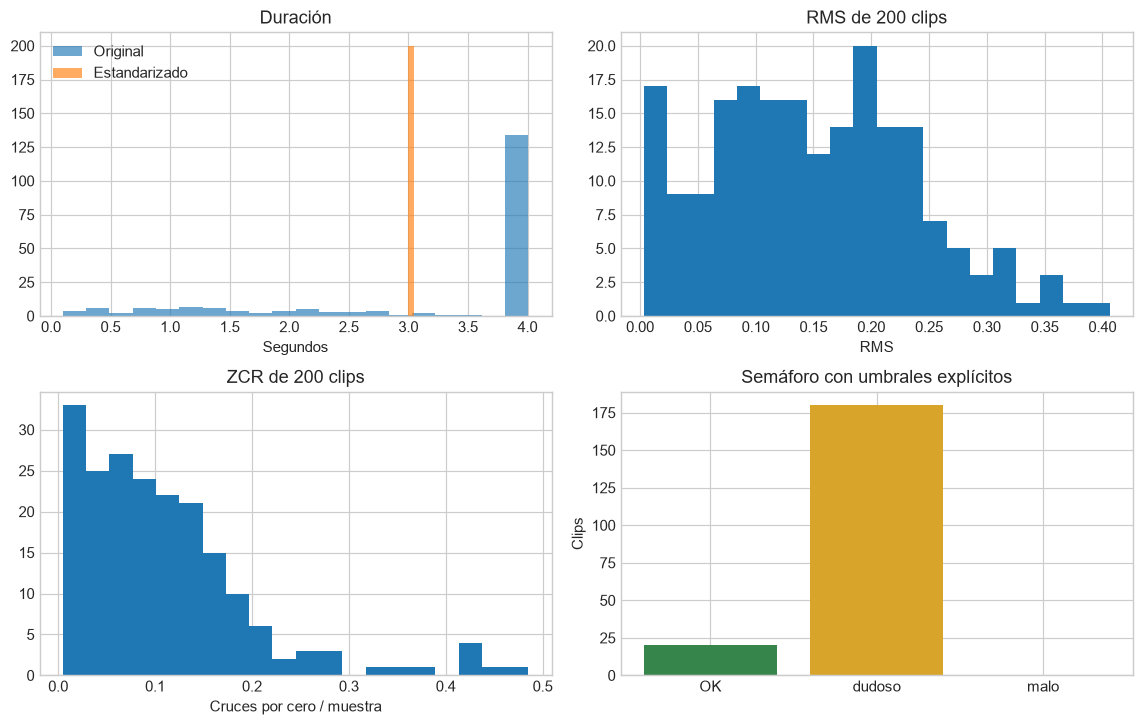

status,OK,dudoso,malo
class_name,,,
air_conditioner,0,20,0
car_horn,0,20,0
children_playing,7,13,0
dog_bark,6,14,0
drilling,3,17,0
engine_idling,0,20,0
gun_shot,1,19,0
jackhammer,2,18,0
siren,1,19,0


In [19]:
def energy_contrast_proxy(y):
    powers = librosa.feature.rms(y=y, frame_length=N_FFT, hop_length=HOP_LENGTH)[0]**2
    low, high = np.percentile(powers, [20, 80])
    return float(10*np.log10((high + 1e-12)/(low + 1e-12)))

QA_THRESHOLDS = {'duration_min_sec': 2.5, 'duration_max_sec': 3.5, 'peak_max': 1.0,
    'min_mfcc_frames_exclusive': 30, 'silence_rms': 1e-5,
    'rms_review_low': 0.01, 'rms_review_high': 0.4,
    'zcr_review_low': 0.005, 'zcr_review_high': 0.35,
    'padding_review_fraction': 0.5, 'cropping_review_fraction': 0.35,
    'source_clipping_review_fraction': 0.001, 'energy_contrast_review_db': 15.0}

def quality_status(row):
    bad, review = [], []
    if not row['finite']: bad.append('valores no finitos')
    if row['peak'] > 1.0 + 1e-6: bad.append('pico fuera de rango')
    if not 2.5 <= row['duration_sec'] <= 3.5: bad.append('duración fuera de objetivo')
    if row['mfcc_frames'] <= 30: bad.append('pocas ventanas MFCC')
    if row['rms'] < QA_THRESHOLDS['silence_rms']: bad.append('silencio')
    if row['rms'] < 0.01 or row['rms'] > 0.4: review.append('RMS extremo')
    if row['zcr'] < 0.005 or row['zcr'] > 0.35: review.append('ZCR extremo')
    if row['pad_fraction'] > 0.5: review.append('mucho padding')
    if row['crop_fraction'] > 0.35: review.append('mucho recorte')
    if row['source_clip_fraction'] > 0.001: review.append('posible saturación en original')
    if row['energy_contrast_proxy_db'] < 15: review.append('contraste bajo; SNR real desconocido')
    return ('malo', '; '.join(bad + review)) if bad else (('dudoso', '; '.join(review)) if review else ('OK', 'controles superados'))

qa_rows = []
for position, record in enumerate(selection.itertuples(), 1):
    path = RAW_DIR / record.relative_path
    y, descriptors, info = process_cached(path)
    row = {'filename': record.slice_file_name, 'relative_path': record.relative_path,
        'fold': record.fold, 'classID': record.classID,
        'sr': TARGET_SR, 'samples': len(y), 'duration_sec': len(y)/TARGET_SR,
        'peak': float(np.max(np.abs(y))), 'finite': bool(np.isfinite(y).all() and np.isfinite(list(descriptors.values())).all()),
        'mfcc_frames': 1 + len(y)//HOP_LENGTH, 'energy_contrast_proxy_db': energy_contrast_proxy(y),
        **info, **descriptors, 'rms': descriptors['rms_mean'], 'zcr': descriptors['zcr_mean']}
    row['status'], row['reasons'] = quality_status(row)
    qa_rows.append(row)
    if position % 50 == 0: print(f'QA: {position}/200')
qa = pd.DataFrame(qa_rows).merge(
    metadata[['slice_file_name', 'class']].rename(columns={'slice_file_name': 'filename', 'class': 'class_name'}),
    on='filename', validate='one_to_one')
assert len(qa) == 200 and qa.finite.all()
assert qa.sr.eq(TARGET_SR).all() and qa.samples.eq(48000).all() and qa.peak.le(1 + 1e-6).all()
qa.to_csv(OUTPUTS['metrics'] / 'qa_200.csv', index=False)
(OUTPUTS['metrics'] / 'qa_thresholds.json').write_text(json.dumps(QA_THRESHOLDS, indent=2), encoding='utf-8')
status_counts = qa.status.value_counts().reindex(['OK', 'dudoso', 'malo'], fill_value=0)
print('Semáforo:'); print(status_counts.to_string())
print('Frames MFCC:', sorted(qa.mfcc_frames.unique().tolist()))
print('Duración original:'); print(qa.source_duration_sec.describe().round(3).to_string())
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0,0].hist(qa.source_duration_sec, bins=20, alpha=0.65, label='Original')
axes[0,0].hist(qa.duration_sec, bins=20, alpha=0.65, label='Estandarizado'); axes[0,0].legend()
axes[0,0].set(title='Duración', xlabel='Segundos')
axes[0,1].hist(qa.rms, bins=20); axes[0,1].set(title='RMS de 200 clips', xlabel='RMS')
axes[1,0].hist(qa.zcr, bins=20); axes[1,0].set(title='ZCR de 200 clips', xlabel='Cruces por cero / muestra')
axes[1,1].bar(status_counts.index, status_counts.values, color=['#36854b', '#d8a429', '#bd4141'])
axes[1,1].set(title='Semáforo con umbrales explícitos', ylabel='Clips')
plt.tight_layout(); plt.show()
pd.crosstab(qa.class_name, qa.status).reindex(columns=['OK','dudoso','malo'], fill_value=0)

In [20]:
# Controles independientes para verificar que QA reconoce fallos evidentes.
control = qa.iloc[0].to_dict()
silent_control = {**control, 'rms': 0.0, 'zcr': 0.0, 'peak': 0.0}
clipped_control = {**control, 'peak': 1.2}
short_control = {**control, 'duration_sec': 0.2, 'mfcc_frames': 7}
assert quality_status(silent_control)[0] == 'malo'
assert quality_status(clipped_control)[0] == 'malo'
assert quality_status(short_control)[0] == 'malo'
print('QA reconoce silencio, picos inválidos y duración/ventanas insuficientes.')
review_columns = ['filename', 'class_name', 'status', 'source_duration_sec', 'rms', 'zcr', 'energy_contrast_proxy_db', 'reasons']
colors = {'OK': '#e0f2df', 'dudoso': '#fff0c2', 'malo': '#ffdada'}
styled_qa = qa[review_columns].style.map(lambda value: 'background-color: '+colors[value], subset=['status']).format(precision=3)
(OUTPUTS['metrics'] / 'qa_dashboard.html').write_text(styled_qa.to_html(), encoding='utf-8')
qa.sort_values(['status', 'filename'])[review_columns].head(15)

QA reconoce silencio, picos inválidos y duración/ventanas insuficientes.


,filename,class_name,status,source_duration_sec,rms,zcr,energy_contrast_proxy_db,reasons
146,103076-3-0-0.wav,dog_bark,OK,2.527188,0.054203,0.062781,51.246336,controles superados
147,114280-3-0-0.wav,dog_bark,OK,4.000000,0.073284,0.097246,66.562239,controles superados
8,147764-4-0-0.wav,drilling,OK,1.700000,0.085925,0.124636,105.130306,controles superados
66,157695-3-0-19.wav,dog_bark,OK,4.000000,0.066993,0.165720,35.974957,controles superados
149,168037-4-0-0.wav,drilling,OK,2.060000,0.069931,0.178950,101.560775,controles superados
194,178261-7-0-0.wav,jackhammer,OK,1.800000,0.110423,0.094773,106.375455,controles superados
88,180125-4-0-16.wav,drilling,OK,4.000000,0.139200,0.187812,21.488687,controles superados
107,190680-3-1-0.wav,dog_bark,OK,1.536689,0.095908,0.072344,106.110989,controles superados
145,196057-2-0-0.wav,children_playing,OK,4.000000,0.142481,0.069923,23.388810,controles superados
164,196058-2-0-0.wav,children_playing,OK,2.797256,0.060595,0.069731,102.590024,controles superados


**Resultado de QA:** 20 OK, 180 dudosos y 0 malos. Un clip dudoso no se descarta: se revisan su audio, clase y motivo. El padding puede aumentar el contraste entre ventanas y un sonido sostenido puede reducirlo; por eso el proxy no certifica “SNR > 15 dB”. El espectro y el objetivo de clasificación también importan. Todas las salidas tienen 3 s, 16 kHz, mono y 94 frames MFCC con `center=True`; la distribución de duración original muestra la información que esa estandarización oculta.

## Reflexiones finales

1. **¿Por qué 16 kHz / 3 s / mono?** Reduce costo y fija una entrada comparable: 48 000 muestras por clip. Mono elimina la dimensión de canales y la localización espacial; 16 kHz conserva hasta 8 kHz y pierde agudos superiores; 3 s puede recortar eventos o introducir ceros. Es una decisión práctica para este ejercicio, no una configuración universal.
2. **¿Qué paso mejoró más la calidad perceptual? ¿Qué quitó y qué preservó?** Para zumbido de 50 Hz el notch permite quitar una banda estrecha y conservar la mayor parte del espectro. El pasa-altos elimina graves de modo más amplio y puede quitar sonido útil; el trim solo elimina bordes de baja energía. Normalizar cambia amplitud, no elimina ruido. Los reproductores y el SNR de los ensayos permiten contrastar estos efectos; no se atribuye una mejora perceptual medida por personas a estas métricas automáticas.
3. **¿Qué ruido se detectó y en qué bandas?** En el experimento se introdujo ruido blanco en toda la banda representable (0–8 kHz) y un zumbido de 50 Hz. Son contaminaciones controladas. Los audios urbanos ya contienen mezclas y fondo: sin referencia ni inspección individual no se afirma que ese fondo sea blanco, hum o impulsivo en todos los originales. Un impulso aparece breve en tiempo y extendido en frecuencia; un zumbido tonal muestra una línea estrecha y posibles armónicos.
4. **¿Qué checks automatizar?** Duración entre 2.5 y 3.5 s, sample rate y canales correctos, valores finitos, pico ≤ 1, más de 30 ventanas MFCC, archivos legibles y métricas de RMS/ZCR. Si hay referencia limpia se puede exigir SNR > 15 dB; si no la hay se conserva un proxy explícito que derive casos a revisión, sin inventar el SNR. Conviene inspeccionar también saturación del original, cuánto se recortó y cuánto padding se agregó.

**Qué muestran los resultados:** la representación del audio depende de cada decisión de preprocesamiento. La extracción de features y la separación de folds deben ser reproducibles. Los aumentos se generan después de separar el test y solo sobre entrenamiento, manteniendo cada archivo fuente y sus variantes juntos. Un resultado sobre 20 clips de test es ilustrativo y no equivale al benchmark oficial de UrbanSound8K.

## Referencias
- [Consigna: Audio como dato](https://juanfkurucz.com/ucu-id/ut4/14-audio/)
- [UrbanSound8K: documentación y folds oficiales](https://urbansounddataset.weebly.com/urbansound8k.html)
- [Dataset utilizado en Kaggle](https://www.kaggle.com/datasets/chrisfilo/urbansound8k)
- [librosa: carga](https://librosa.org/doc/latest/generated/librosa.load.html), [STFT](https://librosa.org/doc/latest/generated/librosa.stft.html), [features](https://librosa.org/doc/latest/feature_extraction.html) y [efectos](https://librosa.org/doc/latest/sequence.html#module-librosa.effects)
- [SciPy: filtros Butterworth](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.butter.html) y [notch](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.iirnotch.html)
- [kagglehub](https://github.com/Kaggle/kagglehub) y [preprocesamiento de scikit-learn](https://scikit-learn.org/stable/modules/preprocessing.html)

In [21]:
# Comprobación final de la entrega y versiones.
from importlib.metadata import version
packages = ['librosa', 'soundfile', 'kagglehub', 'numpy', 'pandas', 'matplotlib', 'scipy', 'scikit-learn']
versions = {package: version(package) for package in packages}
(Path('requirements.txt')).write_text(''.join(f'{package}=={installed}'+chr(10) for package, installed in versions.items()), encoding='utf-8')
assert len(df_features) == 100
assert len(qa) == 200
assert len(df_augmented) == 260
assert set(train.fold).isdisjoint(set(test.fold))
assert set(train.fsID).isdisjoint(set(test.fsID))
assert np.allclose(snr_table.SNR_requested_dB, snr_table.SNR_measured_dB, atol=0.001)
print('100 clips principales; 200 en QA; 160 variantes adicionales solo de entrenamiento.')
print('Análisis A–D, exploraciones E.1–E.3 y desafíos F.1–F.3 completados.')
print(versions)

100 clips principales; 200 en QA; 160 variantes adicionales solo de entrenamiento.
Análisis A–D, exploraciones E.1–E.3 y desafíos F.1–F.3 completados.
{'librosa': '0.11.0', 'soundfile': '0.13.1', 'kagglehub': '1.0.2', 'numpy': '2.5.3', 'pandas': '3.0.6', 'matplotlib': '3.11.2', 'scipy': '1.18.1', 'scikit-learn': '1.9.1'}
